In [ ]:

import pandas as pd
from google.colab import files
archivo = files.upload()

nombre_archivo = list(archivo.keys())[0]
excel = pd.ExcelFile(nombre_archivo)
hoja = excel.sheet_names[0]

print("Archivo cargado:", nombre_archivo)
print("Hoja encontrada:", hoja)
temporal = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=None)
fila_encabezado = None

for i in range(len(temporal)):
    valores = temporal.iloc[i].astype(str).str.strip().tolist()

    if "Local Date Time" in valores:
        fila_encabezado = i
        break

if fila_encabezado is None:
    raise ValueError("No se encontró la columna Local Date Time.")
df = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=fila_encabezado)

df.columns = df.columns.astype(str).str.strip()

print("\nArchivo leído correctamente.")
print("Total de registros:", len(df))
print("\nColumnas encontradas:")
print(df.columns.tolist())


Saving Estacion_2_.xlsx to Estacion_2_.xlsx
Archivo cargado: Estacion_2_.xlsx
Hoja encontrada: Sheet1

Archivo leído correctamente.
Total de registros: 4659

Columnas encontradas:
['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']


In [ ]:
col_fecha = "Local Date Time"
columnas_originales = {
    "Temperatura exterior (C)": "Temperature Outdoor",
    "Presion atmosferica inhg": "Pressure Relative",
    "Humedad relativa (%)": "Humidity Outdoor",
    "Velocidad viento (km/h)": "Wind Average"}


faltantes = [c for c in [col_fecha] + list(columnas_originales.values())
    if c not in df.columns]

if faltantes:raise ValueError(f"Faltan estas columnas: {faltantes}")
df[col_fecha] = pd.to_datetime(
    df[col_fecha],
    errors="coerce")
for nombre_es, nombre_original in columnas_originales.items():

    df[nombre_es] = pd.to_numeric(
        df[nombre_original].astype(str).str.extract(
            r"([-+]?\d*\.?\d+)"
        )[0],
        errors="coerce")
columnas_finales = [
    col_fecha,
    "Temperatura exterior (C)",
    "Presion atmosferica inhg",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df_limpio = df[columnas_finales].copy()
df_limpio = df_limpio.dropna().copy()
df_limpio = df_limpio.sort_values(col_fecha)
df_limpio = df_limpio.reset_index(drop=True)

print("LIMPIEZA COMPLETADA")
print("Registros originales:", len(df))
print("Registros completos:", len(df_limpio))
print("Registros eliminados:", len(df) - len(df_limpio))

print("\nDatos vacíos:")
print(df_limpio.isnull().sum())

display(df_limpio.head())


LIMPIEZA COMPLETADA
Registros originales: 4659
Registros completos: 4659
Registros eliminados: 0

Datos vacíos:
Local Date Time             0
Temperatura exterior (C)    0
Presion atmosferica inhg    0
Humedad relativa (%)        0
Velocidad viento (km/h)     0
dtype: int64


,Local Date Time,Temperatura exterior (C),Presion atmosferica inhg,Humedad relativa (%),Velocidad viento (km/h)
0,2026-10-10 00:05:00,8.2,29.93,95,0.0
1,2026-10-10 00:10:00,8.1,29.93,95,0.0
2,2026-10-10 00:15:00,8.1,29.94,95,0.0
3,2026-10-10 00:20:00,8.0,29.93,96,0.0
4,2026-10-10 00:25:00,7.8,29.93,95,0.0


Sube el archivo Excel de la Estación 2


Saving Estacion_2_.xlsx to Estacion_2_ (2).xlsx
Archivo cargado correctamente.
Hoja utilizada: Sheet1
Columnas encontradas:
['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']

LIMPIEZA DE DATOS
Registros originales: 4659
Registros completos: 4659

Valores vacíos:
Local Date Time              0
Temperatura exterior (C)     0
Presion atmosferica (hPa)    0
Humedad relativa (%)         0
Velocidad viento (km/h)      0
dtype: int64

REGISTROS PARA LA GRÁFICA DE PRESIÓN
Desde: 2026-10-17 00:00:00
Hasta: 2026-10-27 23:59:59
Cantidad de registros: 2839


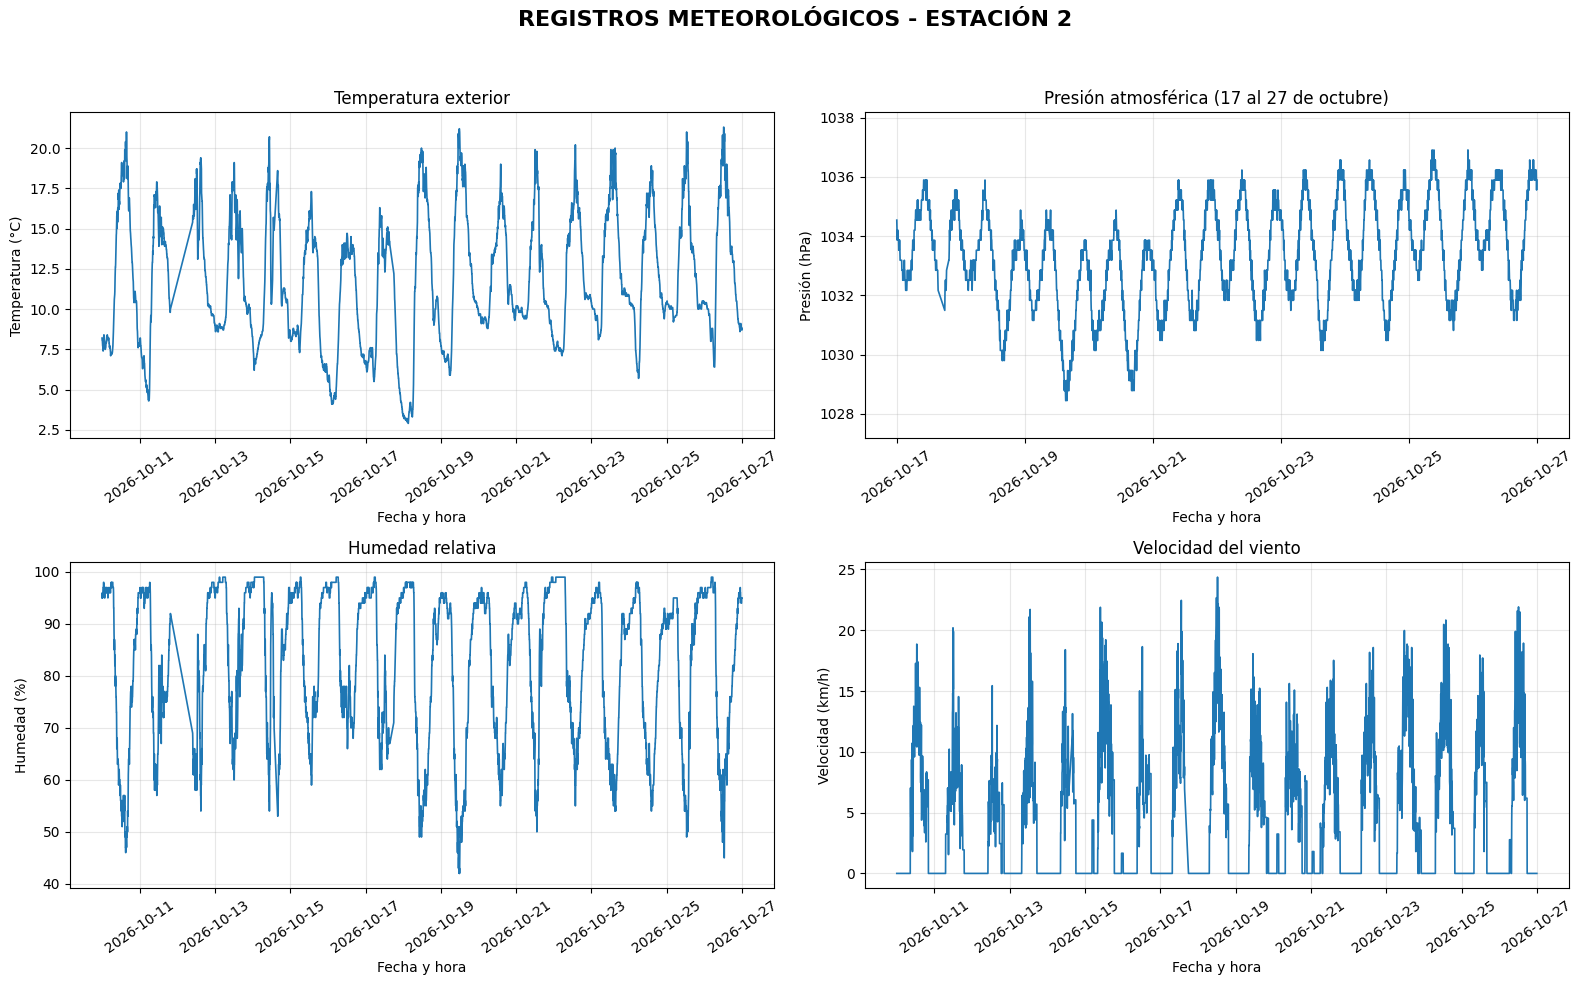


RESUMEN ESTADÍSTICO - ESTACIÓN 2
       Temperatura exterior (C)  Presion atmosferica (hPa)  \
count                   4659.00                    4659.00   
mean                      11.79                    1026.29   
std                        3.99                       9.51   
min                        2.90                    1012.87   
25%                        8.90                    1013.89   
50%                       10.90                    1031.83   
75%                       14.90                    1033.86   
max                       21.30                    1036.91   

       Humedad relativa (%)  Velocidad viento (km/h)  
count               4659.00                  4659.00  
mean                  82.72                     4.32  
std                   14.59                     5.35  
min                   42.00                     0.00  
25%                   71.00                     0.00  
50%                   88.00                     0.00  
75%                   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

print("Sube el archivo Excel de la Estación 2")
archivos = files.upload()

nombre_archivo = list(archivos.keys())[0]
excel = pd.ExcelFile(nombre_archivo)
hoja = excel.sheet_names[0]
temporal = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=None)
fila_encabezado = None
for i in range(len(temporal)):valores = temporal.iloc[i].astype(str).str.strip().tolist()

    if "Local Date Time" in valores:
        fila_encabezado = i
        break

if fila_encabezado is None:
    raise ValueError(  "No se encontró la columna 'Local Date Time'. "
        "Verifica los encabezados del archivo.")

df = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=fila_encabezado)
df.columns = df.columns.astype(str).str.strip()
print("Archivo cargado correctamente.")
print("Hoja utilizada:", hoja)
print("Columnas encontradas:")
print(df.columns.tolist())

columnas_necesarias = [
    "Local Date Time",
    "Temperature Outdoor",
    "Pressure Relative",
    "Humidity Outdoor",
    "Wind Average"]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}")

df["Local Date Time"] = pd.to_datetime(df["Local Date Time"],errors="coerce")

def convertir_numero(columna):
    valores = (
        df[columna]
        .astype(str)
        .str.extract(r"([-+]?\d*\.?\d+)")[0])

    return pd.to_numeric(valores, errors="coerce")

df["Temperatura exterior (C)"] = convertir_numero(
    "Temperature Outdoor")
presion_inhg = convertir_numero("Pressure Relative")
df["Presion atmosferica (hPa)"] = (
    presion_inhg * 33.8639)
df["Humedad relativa (%)"] = convertir_numero(
    "Humidity Outdoor")
df["Velocidad viento (km/h)"] = convertir_numero(
    "Wind Average")
columnas_finales = [
    "Local Date Time",
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df_limpio = df[columnas_finales].copy()
df_limpio = df_limpio.dropna(
    subset=columnas_finales)
df_limpio = df_limpio.sort_values(
    by="Local Date Time"
).reset_index(drop=True)

print("\nLIMPIEZA DE DATOS")
print("Registros originales:", len(df))
print("Registros completos:", len(df_limpio))
print("\nValores vacíos:")
print(df_limpio.isnull().sum())

if df_limpio.empty:
    raise ValueError(
        "No quedaron registros completos. "
        "Revisa las fechas y los valores del archivo.")

inicio = pd.Timestamp("2026-10-17 00:00:00")
fin = pd.Timestamp("2026-10-28 00:00:00")

df_presion = df_limpio[
    (df_limpio["Local Date Time"] >= inicio) &
    (df_limpio["Local Date Time"] < fin)].copy()

print("\nREGISTROS PARA LA GRÁFICA DE PRESIÓN")
print("Desde:", inicio)
print("Hasta:", "2026-10-27 23:59:59")
print("Cantidad de registros:", len(df_presion))

if df_presion.empty:
    print(
        "ADVERTENCIA: No hay registros de presión "
        "entre el 17 y el 27 de octubre de 2026." )

fig, ejes = plt.subplots(
    2, 2,
    figsize=(16, 10))

fig.suptitle(
    "REGISTROS METEOROLÓGICOS - ESTACIÓN 2",
    fontsize=16,
    fontweight="bold")

ejes[0, 0].plot(
    df_limpio["Local Date Time"],
    df_limpio["Temperatura exterior (C)"],
    linewidth=1.2)

ejes[0, 0].set_title(
    "Temperatura exterior")

ejes[0, 0].set_xlabel("Fecha y hora")
ejes[0, 0].set_ylabel("Temperatura (°C)")
ejes[0, 0].grid(True, alpha=0.3)

if not df_presion.empty:

    ejes[0, 1].plot(
        df_presion["Local Date Time"],
        df_presion["Presion atmosferica (hPa)"],
        linewidth=1.2)

    ejes[0, 1].set_title(
        "Presión atmosférica (17 al 27 de octubre)")
    minimo = df_presion["Presion atmosferica (hPa)"].min()
    maximo = df_presion["Presion atmosferica (hPa)"].max()
    rango = maximo - minimo
    if rango == 0:
        margen = max(abs(minimo) * 0.01, 1)
    else:
        margen = rango * 0.15

    ejes[0, 1].set_ylim(
        minimo - margen,
        maximo + margen)

else:
    ejes[0, 1].text(
        0.5, 0.5,
        "No hay registros en el periodo seleccionado",
        ha="center",
        va="center",
        transform=ejes[0, 1].transAxes)

    ejes[0, 1].set_title(
        "Presión atmosférica (17 al 27 de octubre)")

ejes[0, 1].set_xlabel("Fecha y hora")
ejes[0, 1].set_ylabel("Presión (hPa)")
ejes[0, 1].grid(True, alpha=0.3)

ejes[1, 0].plot(
    df_limpio["Local Date Time"],
    df_limpio["Humedad relativa (%)"],
    linewidth=1.2)

ejes[1, 0].set_title(
    "Humedad relativa")

ejes[1, 0].set_xlabel("Fecha y hora")
ejes[1, 0].set_ylabel("Humedad (%)")
ejes[1, 0].grid(True, alpha=0.3)

ejes[1, 1].plot(
    df_limpio["Local Date Time"],
    df_limpio["Velocidad viento (km/h)"],
    linewidth=1.2)

ejes[1, 1].set_title(
    "Velocidad del viento")

ejes[1, 1].set_xlabel("Fecha y hora")
ejes[1, 1].set_ylabel("Velocidad (km/h)")
ejes[1, 1].grid(True, alpha=0.3)
for eje in ejes.flat:
    eje.tick_params(axis="x", rotation=35)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nRESUMEN ESTADÍSTICO - ESTACIÓN 2")

print(df_limpio[
        ["Temperatura exterior (C)",
            "Presion atmosferica (hPa)",
            "Humedad relativa (%)",
            "Velocidad viento (km/h)"
        ] ].describe().round(2))

nombre_salida = "Estacion_2_datos_limpios.xlsx"

df_limpio.to_excel(
    nombre_salida,
    index=False)
print("\nArchivo limpio generado:", nombre_salida)

files.download(nombre_salida)


ENTRENAMIENTO DE MODELOS


Sube el archivo original de la Estación 2


Saving Estacion_2_.xlsx to Estacion_2_ (6).xlsx

Datos cargados correctamente
Cantidad de registros: 4659
Columnas: ['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']

Registros completos: 4659

ENTRENANDO SVR PARA: Temperatura exterior (C)

Mejores parámetros:
{'svr__C': 100, 'svr__epsilon': 0.2, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

RESULTADOS:
R²: 0.9948
MAE: 0.1728
MSE: 0.0644
RMSE: 0.2537
Ajuste estimado: 98.62%

ENTRENANDO SVR PARA: Presion atmosferica (hPa)

Mejores parámetros:
{'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

RESULTADOS:
R²: 0.9479
MAE: 0.2880
MSE: 0.1

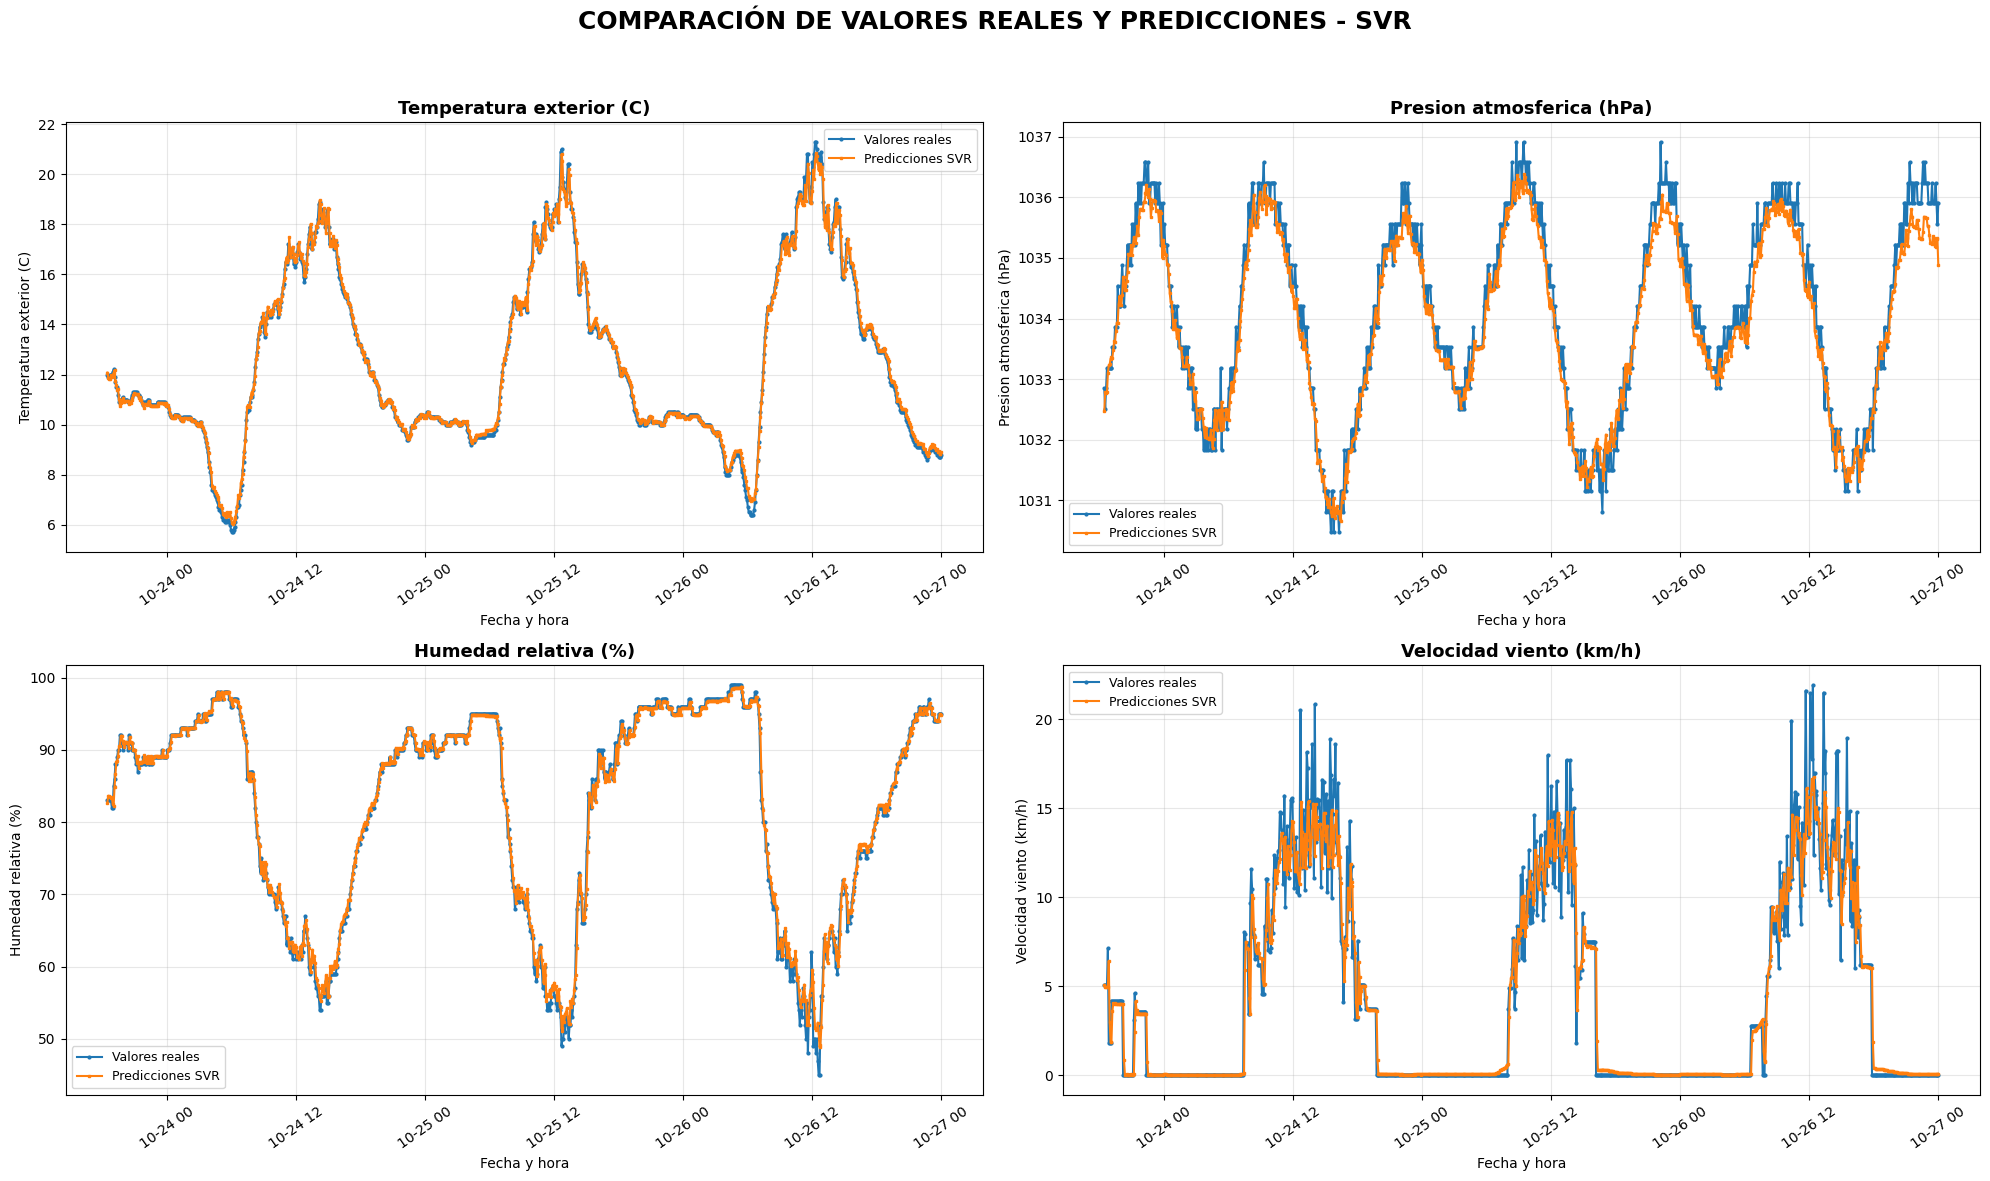


RESUMEN GENERAL DEL MODELO SVR - ESTACIÓN 2


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9948,0.1728,0.0644,0.2537,98.6184
1,Presion atmosferica (hPa),0.9479,0.2880,0.1326,0.3641,99.9721
2,Humedad relativa (%),0.9924,0.8115,1.5965,1.2635,99.0101
3,Velocidad viento (km/h),0.9121,0.8473,2.8576,1.6904,80.3952



ENTRENAMIENTO SVR FINALIZADO CORRECTAMENTE

RESUMEN DE RESULTADOS:


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9948,0.1728,0.0644,0.2537,98.6184
1,Presion atmosferica (hPa),0.9479,0.2880,0.1326,0.3641,99.9721
2,Humedad relativa (%),0.9924,0.8115,1.5965,1.2635,99.0101
3,Velocidad viento (km/h),0.9121,0.8473,2.8576,1.6904,80.3952


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

print("Sube el archivo original de la Estación 2")
archivos = files.upload()
nombre_archivo = list(archivos.keys())[0]

excel = pd.ExcelFile(nombre_archivo)
hoja = excel.sheet_names[0]
temporal = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=None)

fila_encabezado = None

for i in range(len(temporal)):
    valores = temporal.iloc[i].astype(str).str.strip().tolist()

    if "Local Date Time" in valores:
        fila_encabezado = i
        break

if fila_encabezado is None:
    raise ValueError("No se encontró la fila de encabezados.")

df = pd.read_excel(nombre_archivo,sheet_name=hoja,header=fila_encabezado)
df.columns = df.columns.astype(str).str.strip()

print("\nDatos cargados correctamente")
print("Cantidad de registros:", len(df))
print("Columnas:", df.columns.tolist())
columnas_originales = [
    "Local Date Time",
    "Temperature Outdoor",
    "Pressure Relative",
    "Humidity Outdoor",
    "Wind Average"]

faltantes = [c for c in columnas_originalesif c not in df.columns]
if faltantes: raise ValueError(f"Faltan columnas originales: {faltantes}")

df["Local Date Time"] = pd.to_datetime(
    df["Local Date Time"],
    errors="coerce")

def convertir_numero(columna):
    valores = df[columna].astype(str).str.extract(
        r"([-+]?\d*\.?\d+)")[0]

    return pd.to_numeric(valores, errors="coerce")

df["Temperatura exterior (C)"] = convertir_numero(
    "Temperature Outdoor")
df["Presion atmosferica (hPa)"] = (
    convertir_numero("Pressure Relative") * 33.8639)
df["Humedad relativa (%)"] = convertir_numero(
    "Humidity Outdoor")
df["Velocidad viento (km/h)"] = convertir_numero(
    "Wind Average")

variables = [ "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df = df.dropna(
    subset=["Local Date Time"] + variables).sort_values("Local Date Time").reset_index(drop=True)
print("\nRegistros completos:", len(df))
if len(df) < 20:
    raise ValueError("Hay muy pocos registros para entrenar.")

df["hora"] = (
    df["Local Date Time"].dt.hour
    + df["Local Date Time"].dt.minute / 60)

df["dia"] = df["Local Date Time"].dt.dayofyear
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)
df["dia_sin"] = np.sin(2 * np.pi * df["dia"] / 365.25)
df["dia_cos"] = np.cos(2 * np.pi * df["dia"] / 365.25)
for col in variables:
    df[col + "_lag1"] = df[col].shift(1)
    df[col + "_lag2"] = df[col].shift(2)

df = df.dropna().reset_index(drop=True)
caracteristicas = [
    "Temperatura exterior (C)_lag1",
    "Temperatura exterior (C)_lag2",
    "Presion atmosferica (hPa)_lag1",
    "Presion atmosferica (hPa)_lag2",
    "Humedad relativa (%)_lag1",
    "Humedad relativa (%)_lag2",
    "Velocidad viento (km/h)_lag1",
    "Velocidad viento (km/h)_lag2",
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]
parametros = {
    "svr__C": [1, 10, 100],
    "svr__epsilon": [0.01, 0.1, 0.2],
    "svr__gamma": ["scale", 0.01, 0.1],
    "svr__kernel": ["rbf"]}
resultados = []
predicciones = {}
modelos_entrenados = {}

fig, ejes = plt.subplots(
    2, 2,
    figsize=(20, 12))
ejes = ejes.flatten(
for posicion, variable in enumerate(variables):

    print("\n" + "=" * 60)
    print("ENTRENANDO SVR PARA:", variable)
    print("=" * 60)

    X = df[caracteristicas]
    y = df[variable]
    corte = int(len(df) * 0.80)

    X_train = X.iloc[:corte]
    X_test = X.iloc[corte:]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]
    pipeline = Pipeline([
        ("escalador", StandardScaler()),
        ("svr", SVR())])

    # Búsqueda de mejores parámetros
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="neg_mean_absolute_error",
        cv=3,
        n_jobs=-1)

    busqueda.fit(X_train, y_train)

    mejor_modelo = busqueda.best_estimator_
    y_pred = mejor_modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    media_real = np.mean(np.abs(y_test))

    if media_real > 0:
        ajuste = max(
            0,
            100 * (1 - mae / media_real))
    else:
        ajuste = np.nan

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = mejor_modelo
    fechas_test = df["Local Date Time"].iloc[corte:]
    predicciones[variable] = pd.DataFrame({
        "Fecha y hora": fechas_test.values,
        "Valor real": y_test.values,
        "Prediccion SVR": y_pred})

    print("\nMejores parámetros:")
    print(busqueda.best_params_)

    print("\nRESULTADOS:")
    print(f"R²: {r2:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Ajuste estimado: {ajuste:.2f}%")

    ax = ejes[posicion]
    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones SVR",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(
        variable,
        fontsize=13,
        fontweight="bold")

    ax.set_xlabel("Fecha y hora", fontsize=10)
    ax.set_ylabel(variable, fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - SVR",
    fontsize=18,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
tabla_resultados = pd.DataFrame(resultados)

print("\n" + "=" * 70)
print("RESUMEN GENERAL DEL MODELO SVR - ESTACIÓN 2")
print("=" * 70)
display(tabla_resultados.round(4))
print("\nENTRENAMIENTO SVR FINALIZADO CORRECTAMENTE")

print("\nRESUMEN DE RESULTADOS:")
display(tabla_resultados.round(4))


Registros para entrenamiento: 3724
Registros para prueba: 931

Entrenando Random Forest para: Temperatura exterior (C)
R²: 0.9943
MAE: 0.1739
MSE: 0.0706
RMSE: 0.2657
Ajuste estimado: 98.61 %

Entrenando Random Forest para: Presion atmosferica (hPa)
R²: 0.9472
MAE: 0.286
MSE: 0.1345
RMSE: 0.3667
Ajuste estimado: 99.97 %

Entrenando Random Forest para: Humedad relativa (%)
R²: 0.991
MAE: 0.8822
MSE: 1.8914
RMSE: 1.3753
Ajuste estimado: 98.92 %

Entrenando Random Forest para: Velocidad viento (km/h)
R²: 0.9112
MAE: 0.872
MSE: 2.8911
RMSE: 1.7003
Ajuste estimado: 79.82 %

RESULTADOS GENERALES - RANDOM FOREST


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9943,0.1739,0.0706,0.2657,98.6091
1,Presion atmosferica (hPa),0.9472,0.2860,0.1345,0.3667,99.9723
2,Humedad relativa (%),0.9910,0.8822,1.8914,1.3753,98.9238
3,Velocidad viento (km/h),0.9112,0.8720,2.8911,1.7003,79.8205


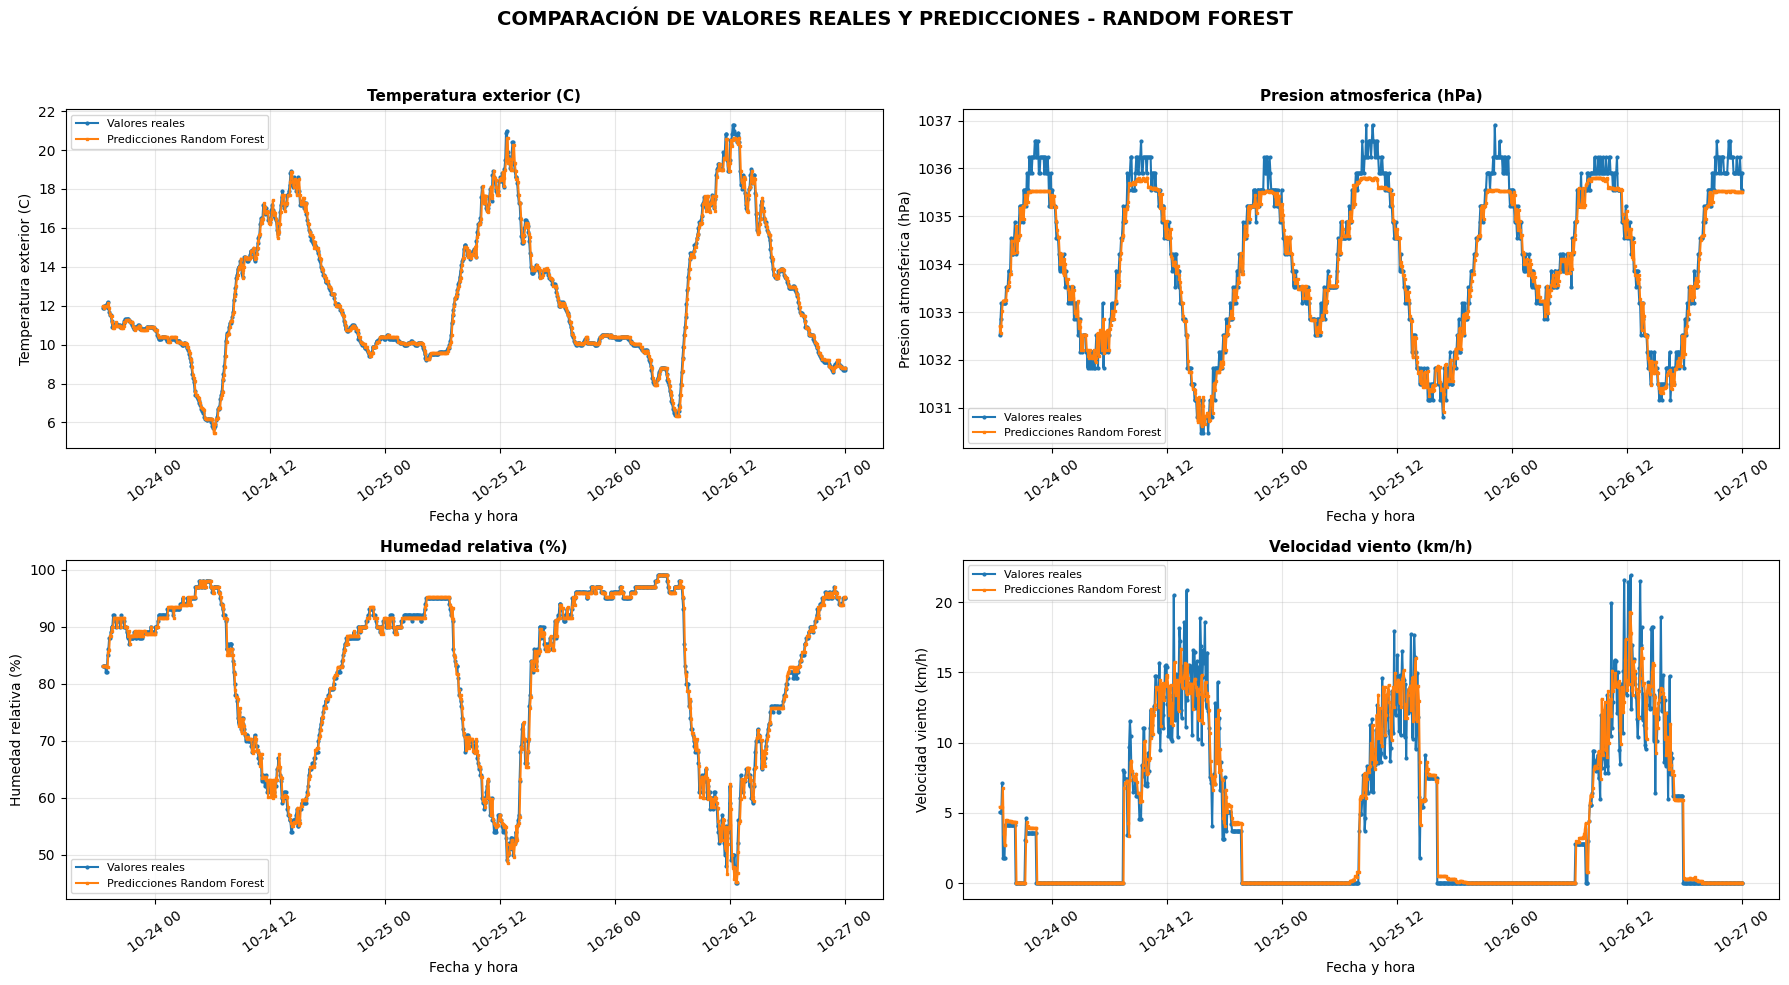


ENTRENAMIENTO RANDOM FOREST FINALIZADO


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)
variables = [
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime(
    datos["Local Date Time"],
    errors="coerce")

datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)

datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear
datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)
datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)
caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))
resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Random Forest para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_leaf_nodes=40,
        random_state=42,
        n_jobs=-1)

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste })

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - RANDOM FOREST")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5 )

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones Random Forest",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - RANDOM FOREST",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
print("\nENTRENAMIENTO RANDOM FOREST FINALIZADO")


Registros para entrenamiento: 3724
Registros para prueba: 931

Entrenando Gradient Boosting para: Temperatura exterior (C)
R²: 0.9947
MAE: 0.165
MSE: 0.0662
RMSE: 0.2573
Ajuste estimado: 98.68 %

Entrenando Gradient Boosting para: Presion atmosferica (hPa)
R²: 0.9419
MAE: 0.3013
MSE: 0.148
RMSE: 0.3847
Ajuste estimado: 99.97 %

Entrenando Gradient Boosting para: Humedad relativa (%)
R²: 0.9921
MAE: 0.8211
MSE: 1.6625
RMSE: 1.2894
Ajuste estimado: 99.0 %

Entrenando Gradient Boosting para: Velocidad viento (km/h)
R²: 0.9101
MAE: 0.9228
MSE: 2.9254
RMSE: 1.7104
Ajuste estimado: 78.65 %

RESULTADOS GENERALES - GRADIENT BOOSTING


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9947,0.1650,0.0662,0.2573,98.6804
1,Presion atmosferica (hPa),0.9419,0.3013,0.1480,0.3847,99.9709
2,Humedad relativa (%),0.9921,0.8211,1.6625,1.2894,98.9983
3,Velocidad viento (km/h),0.9101,0.9228,2.9254,1.7104,78.6452


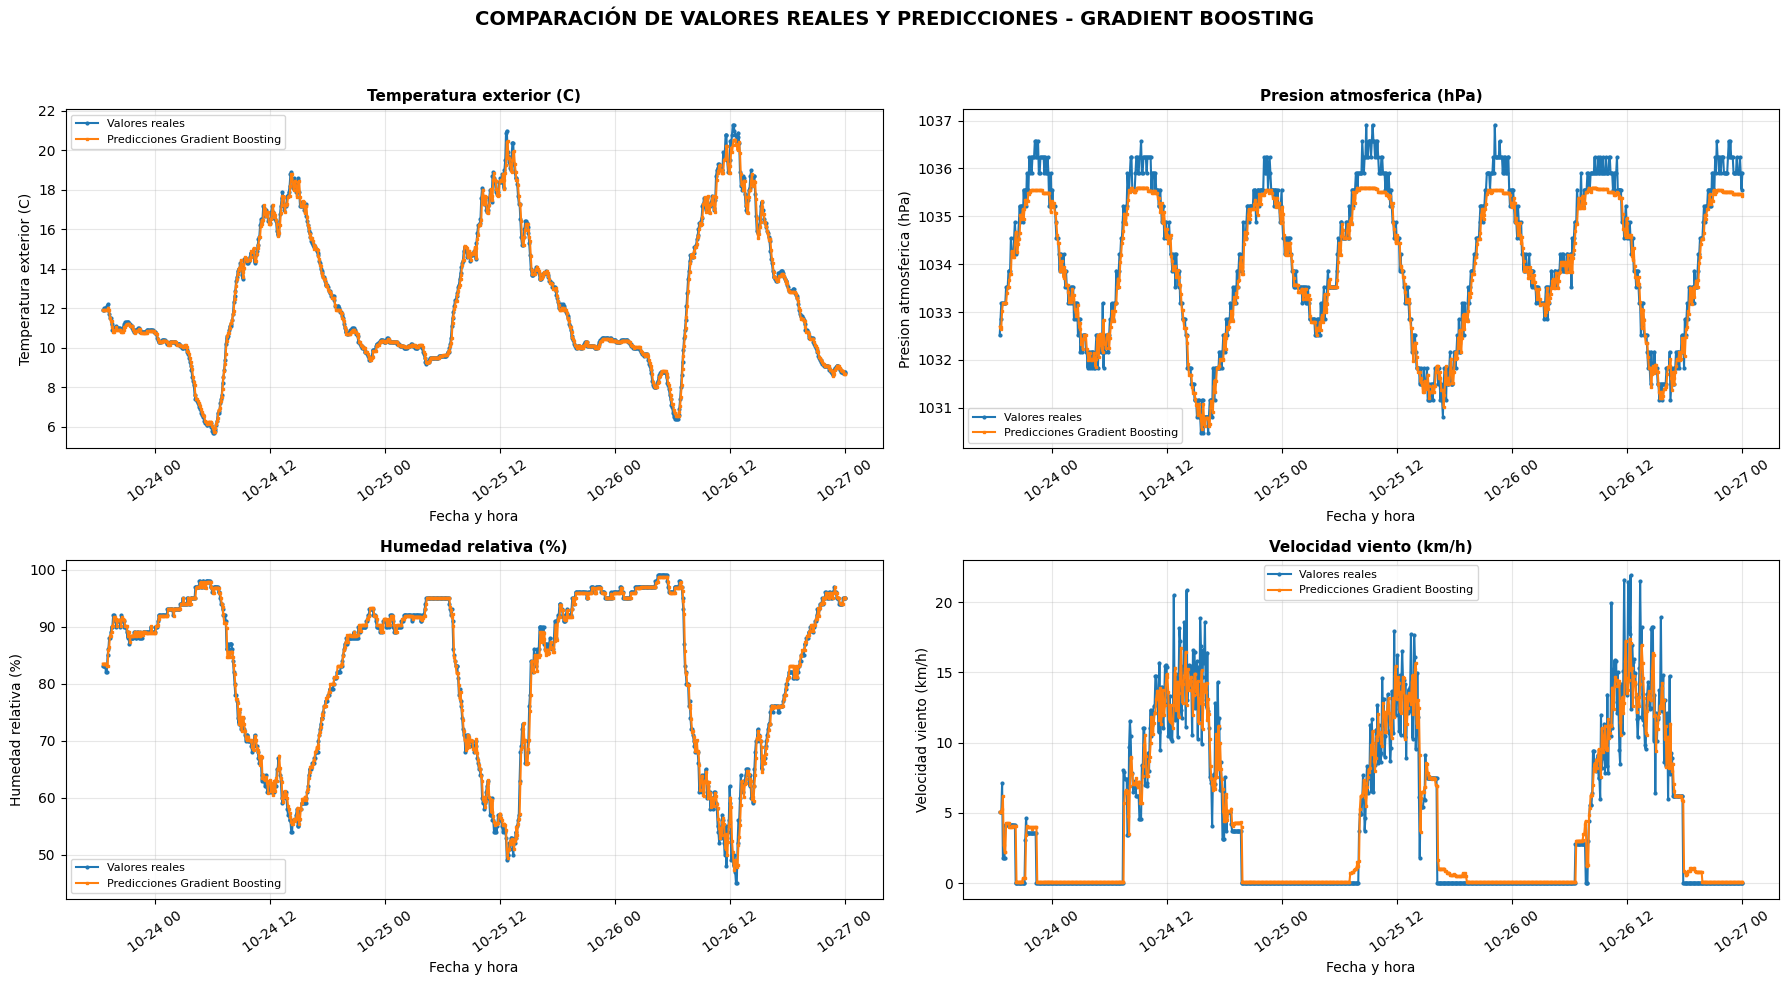


ENTRENAMIENTO GRADIENT BOOSTING FINALIZADO


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)
variables = ["Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime(
    datos["Local Date Time"],
    errors="coerce")
datos = datos.dropna(
    subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)
datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)
for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)
caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Gradient Boosting para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=1,
        loss="squared_error",
        random_state=42)

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)
print("\nRESULTADOS GENERALES - GRADIENT BOOSTING")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones Gradient Boosting",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - GRADIENT BOOSTING",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nENTRENAMIENTO GRADIENT BOOSTING FINALIZADO")


Registros para entrenamiento: 3724
Registros para prueba: 931

Entrenando Regresión Lineal para: Temperatura exterior (C)
R²: 0.9957
MAE: 0.1478
MSE: 0.0536
RMSE: 0.2316
Ajuste estimado: 98.82 %

Entrenando Regresión Lineal para: Presion atmosferica (hPa)
R²: 0.966
MAE: 0.2315
MSE: 0.0866
RMSE: 0.2943
Ajuste estimado: 99.98 %

Entrenando Regresión Lineal para: Humedad relativa (%)
R²: 0.9933
MAE: 0.7722
MSE: 1.4072
RMSE: 1.1863
Ajuste estimado: 99.06 %

Entrenando Regresión Lineal para: Velocidad viento (km/h)
R²: 0.9084
MAE: 0.9717
MSE: 2.9799
RMSE: 1.7262
Ajuste estimado: 77.51 %

RESULTADOS GENERALES - REGRESIÓN LINEAL


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9957,0.1478,0.0536,0.2316,98.8183
1,Presion atmosferica (hPa),0.9660,0.2315,0.0866,0.2943,99.9776
2,Humedad relativa (%),0.9933,0.7722,1.4072,1.1863,99.0579
3,Velocidad viento (km/h),0.9084,0.9717,2.9799,1.7262,77.5135


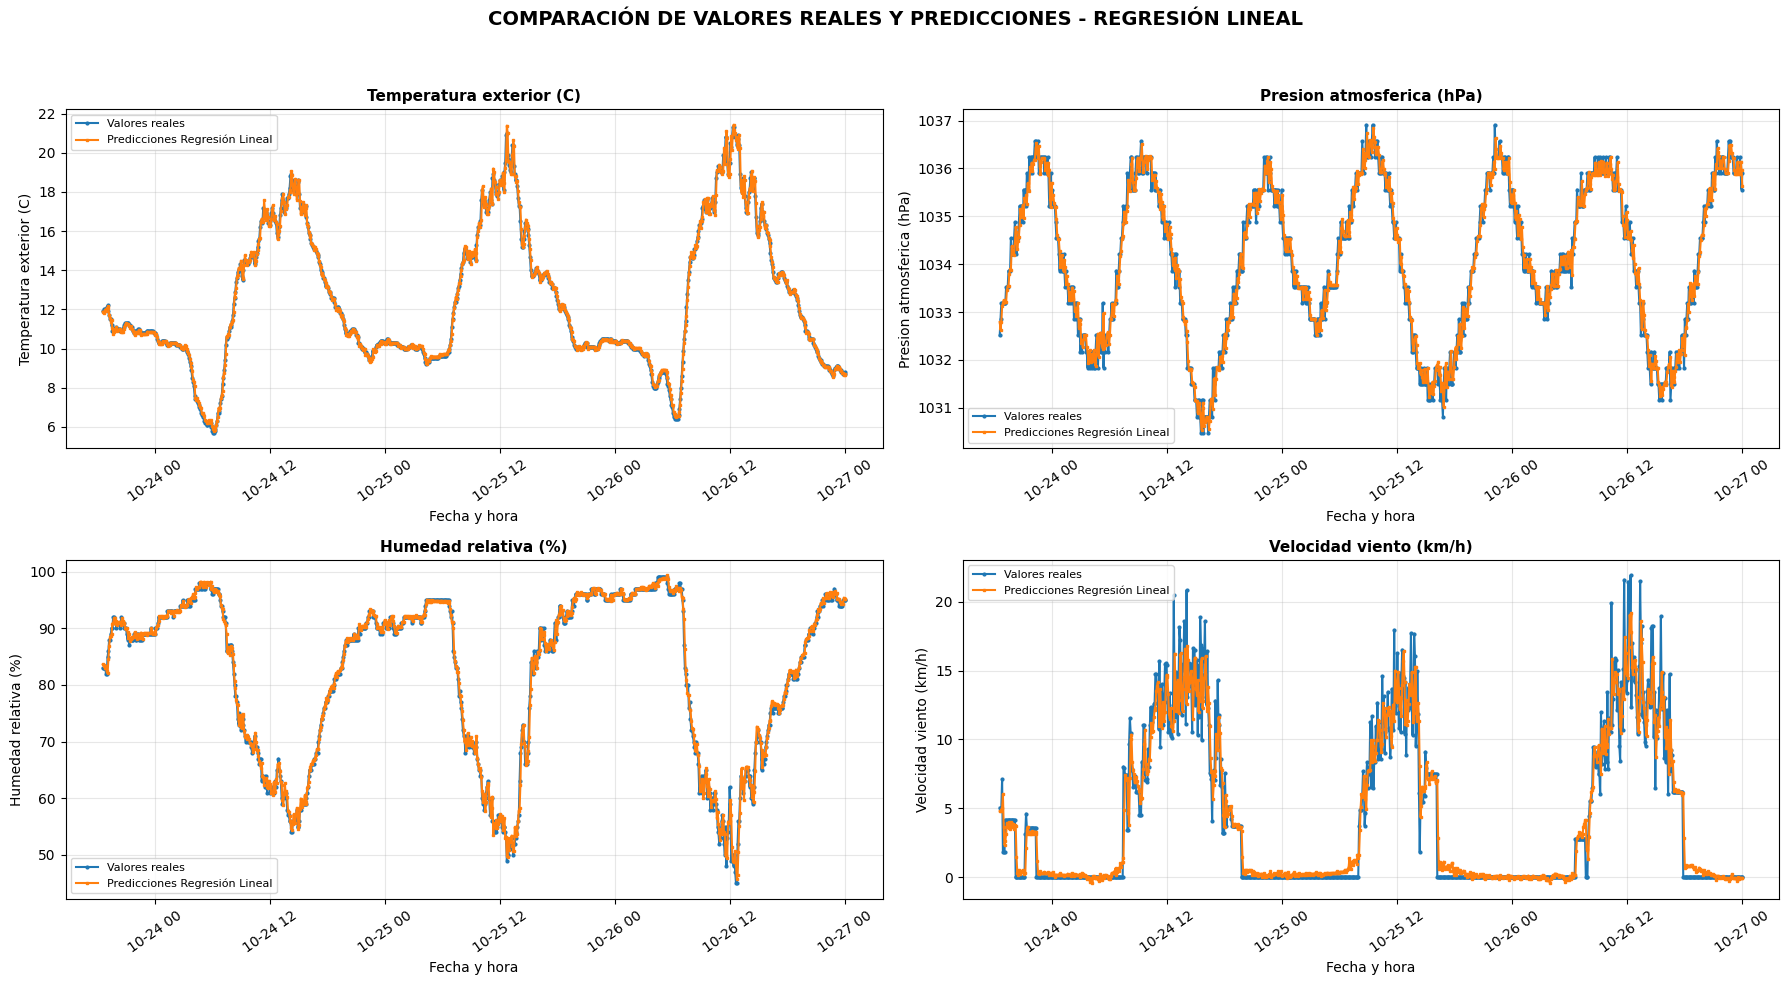


ENTRENAMIENTO REGRESIÓN LINEAL FINALIZADO


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = ["Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime(
    datos["Local Date Time"],
    errors="coerce")
datos = datos.dropna(
    subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)
datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)
for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)
caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Regresión Lineal para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = LinearRegression()
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0
    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste })
    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - REGRESIÓN LINEAL")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot( fechas_test,
        y_pred,
        label="Predicciones Regresión Lineal",
        marker="s",
        markersize=2,
        linewidth=1.5 )

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - REGRESIÓN LINEAL",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
print("\nENTRENAMIENTO REGRESIÓN LINEAL FINALIZADO")


Registros para entrenamiento: 3724
Registros para prueba: 931

Entrenando Árbol de Decisión para: Temperatura exterior (C)
R²: 0.9932
MAE: 0.2037
MSE: 0.0837
RMSE: 0.2893
Ajuste estimado: 98.37 %

Entrenando Árbol de Decisión para: Presion atmosferica (hPa)
R²: 0.9413
MAE: 0.3015
MSE: 0.1495
RMSE: 0.3866
Ajuste estimado: 99.97 %

Entrenando Árbol de Decisión para: Humedad relativa (%)
R²: 0.9887
MAE: 1.0002
MSE: 2.3733
RMSE: 1.5406
Ajuste estimado: 98.78 %

Entrenando Árbol de Decisión para: Velocidad viento (km/h)
R²: 0.891
MAE: 0.9478
MSE: 3.5474
RMSE: 1.8834
Ajuste estimado: 78.07 %

RESULTADOS GENERALES - ÁRBOL DE DECISIÓN


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9932,0.2037,0.0837,0.2893,98.3711
1,Presion atmosferica (hPa),0.9413,0.3015,0.1495,0.3866,99.9708
2,Humedad relativa (%),0.9887,1.0002,2.3733,1.5406,98.7799
3,Velocidad viento (km/h),0.8910,0.9478,3.5474,1.8834,78.0659


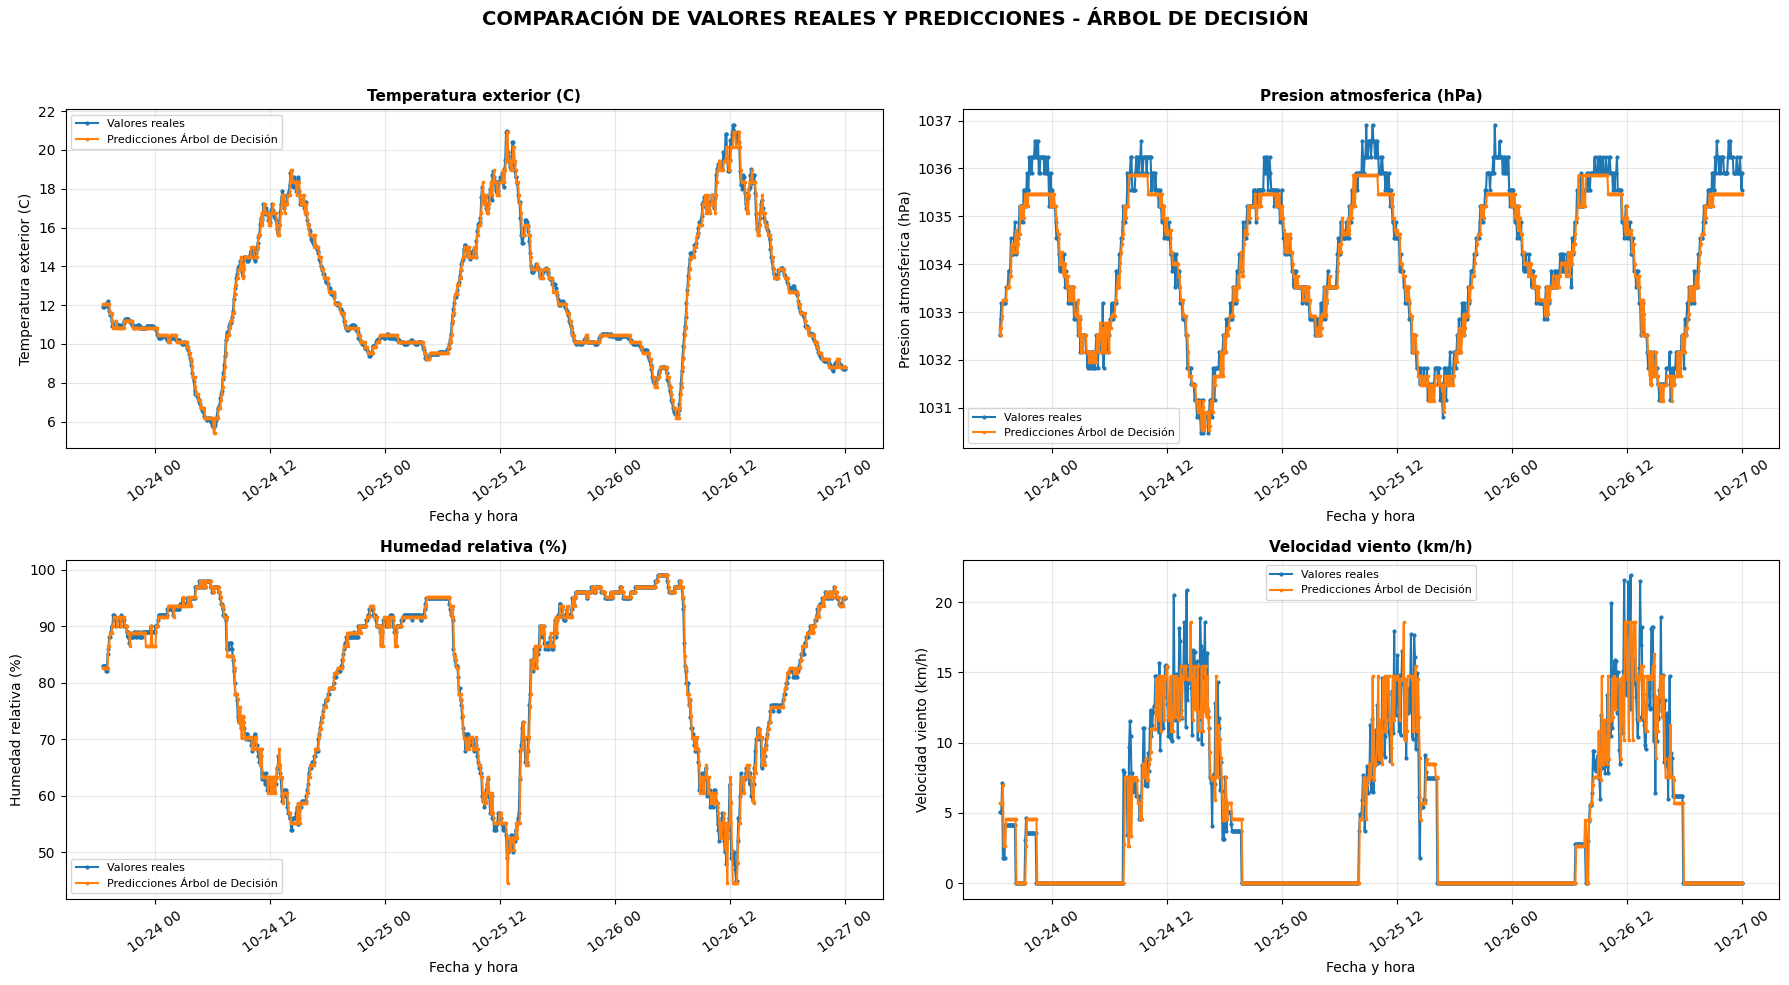


ENTRENAMIENTO ÁRBOL DE DECISIÓN FINALIZADO


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = ["Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime(
    datos["Local Date Time"],
    errors="coerce")

datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)

datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)
caracteristicas = []
for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Árbol de Decisión para:", variable)
    y = datos[variable]
    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = DecisionTreeRegressor(
        max_leaf_nodes=40,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42)

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({"Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - ÁRBOL DE DECISIÓN")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot( fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(fechas_test,
        y_pred,
        label="Predicciones Árbol de Decisión",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - ÁRBOL DE DECISIÓN",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
print("\nENTRENAMIENTO ÁRBOL DE DECISIÓN FINALIZADO")
